# Grad-CAM on the image-only model

**Question:** where in the MRI crop does the image-only model (a 3D convolutional neural network, CNN) get the evidence for its prediction, and how far can the resulting heatmaps be trusted?

**Grad-CAM** (gradient-weighted class activation mapping) is a method that produces a heatmap showing which parts of the input the model's output is most sensitive to. It does not say why a tumor is mutant. It only shows where the model's score responds most strongly.

**Setup that stays fixed throughout**
- **Model:** the five saved `cnn_v2` fold models. Each patient is explained by the model that did not train on them, so no heatmap comes from a model that has seen that patient.
- **Tumor mask:** used only afterwards, to measure where the heat falls. It is never given to the model.
- **Which evidence is shown:** the model gives one score per patient. Heatmaps show evidence *for mutant*. For patients predicted wildtype, the figures show evidence *for wildtype* instead.

**Fixed before looking at results**
- **Prediction Groups:** TP = predicted mutant and truly mutant. FP = predicted mutant but truly wildtype. FN = predicted wildtype but truly mutant. TN = predicted wildtype and truly wildtype. Uses the same cutoff as the rest of the project: the mutant rate among the training patients.
- **Example patients:** one per group, chosen by a random draw with seed 42.

**Not claimed here:** causation, biology, or which of the four scan types matters (the model mixes them from the first layer).

## Setup

All imports, constants and helper functions are in the next two cells. 

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from src.config import RESULTS, OOF_PATH, PROCESSED, MIN_TUMOR_VOXELS
from src.cnn import SmallCNN, GliomaCrops

SEED = 42
LAYER_MAIN = "8x8x8 (pre-pool)"      # layer used for the figures

In [2]:
_models = {}
def get_model(k):
    """Image-only fold-k model, loaded once. In-place ReLU is switched off so autograd can
    keep the activations (it changes nothing in the forward result)."""
    if k not in _models:
        ckpt = torch.load(Path(RESULTS) / "cnn_v2" / f"fold{k}.pt", map_location="cpu")
        state = ckpt["state"] if isinstance(ckpt, dict) and "state" in ckpt else ckpt
        m = SmallCNN()
        m.load_state_dict(state)
        m.eval()                                   # batch norm uses running statistics, dropout off
        for mod in m.modules():
            if isinstance(mod, nn.ReLU):
                mod.inplace = False
        _models[k] = m
    return _models[k]

def layers_for(m):
    """The two layers explained: 8x8x8 (one cell = 16 mm) and the final 4x4x4 (32 mm)."""
    return {"8x8x8 (pre-pool)": m.features[6][2], "4x4x4 (final)": m.features[6]}


def grad_cam(model, image, layers, sign=1.0):
    """Grad-CAM for the single logit. sign=+1: evidence for mutant; sign=-1: evidence for wildtype.
    image: float tensor (4, 128, 128, 128). Returns the logit and one 128^3 numpy map per layer."""
    acts = {}
    handles = [m.register_forward_hook(lambda mod, inp, out, n=n: acts.__setitem__(n, out))
               for n, m in layers.items()]
    try:
        logit = model(image.unsqueeze(0)).squeeze()          # gradients ON (no torch.no_grad)
    finally:
        for h in handles:
            h.remove()
    grads = torch.autograd.grad(logit, list(acts.values()))  # d(logit) / d(feature map)
    cams = {}
    for (name, A), g in zip(acts.items(), grads):
        w = g.mean(dim=(2, 3, 4), keepdim=True)                       # one weight per channel
        cam = torch.relu(sign * (w * A).sum(dim=1, keepdim=True))     # weighted sum, positive part
        cam = F.interpolate(cam, size=(128, 128, 128), mode="trilinear", align_corners=False)
        cams[name] = cam[0, 0].detach().numpy()
    return float(logit.detach()), cams

# one patient, and where the map's mass sits
def load_case(pid):
    """Image (float32 tensor, 4 x 128^3), tumor mask (bool, evaluation only), brain mask (bool)."""
    image = GliomaCrops([pid], [0])[0][0].float()            # the label is a dummy and unused
    with np.load(PROCESSED / f"{pid}.npz") as f:
        tumor = f["mask"].astype(bool)
    brain = (image.numpy() != 0).any(axis=0)                 # background is exactly 0 after normalization
    return image, tumor, brain

def summarize(cam, tumor, brain):
    """Fraction of the map's total mass in tumor / other brain / outside brain, and the enrichment:
    tumor share of the map's brain mass divided by the tumor's share of brain voxels."""
    total = cam.sum()
    if total <= 0:
        return None                                          # all-zero map: nothing to place
    brain = brain | tumor                                    # no tumor voxel counted as background
    regions = {"tumor": tumor, "brain_other": brain & ~tumor, "outside_brain": ~brain}
    out = {f"mass_{name}": float(cam[m].sum() / total) for name, m in regions.items()}
    brain_mass = out["mass_tumor"] + out["mass_brain_other"]
    out["tumor_share_of_brain_mass"] = out["mass_tumor"] / brain_mass if brain_mass > 0 else np.nan
    out["tumor_share_of_brain_vol"] = float(tumor.sum() / brain.sum())
    out["enrichment"] = out["tumor_share_of_brain_mass"] / out["tumor_share_of_brain_vol"]
    return out

def mass_table(patients, model_for, mask_for=None, check_saved=False):
    """Run Grad-CAM for every patient and summarize where the mass sits.
    model_for(row) -> model;  mask_for(pid, brain) -> replacement tumor mask (control only);
    check_saved: confirm the probability equals the saved out-of-fold value (right fold model used)."""
    rows, worst, t0 = [], 0.0, time.time()
    for r in patients.itertuples():
        image, tumor, brain = load_case(r.patient_id)
        if mask_for is not None:
            tumor = mask_for(r.patient_id, brain)
            if tumor.sum() < MIN_TUMOR_VOXELS:
                continue
        m = model_for(r)
        logit, cams = grad_cam(m, image, layers_for(m))
        if check_saved:
            worst = max(worst, abs(1 / (1 + np.exp(-logit)) - r.image_cnn_v2_prob))
        for name, c in cams.items():
            s = summarize(c, tumor, brain)
            if s is not None:
                rows.append({"patient_id": r.patient_id, "group": r.group, "layer": name, **s})
    msg = f"{len(patients)} patients in {time.time() - t0:.0f} s"
    if check_saved:
        msg += f"; max |probability - saved| = {worst:.1e}"
    print(msg)
    return pd.DataFrame(rows)

## 1. Layer choice

Grad-CAM can be computed at any convolutional layer, and deeper layers are typically more specific to the prediction but coarser. Two are used here: the final 4 x 4 x 4 layer (one cell = 32 mm) and the pre-pool 8 x 8 x 8 layer (one cell = 16 mm). The finer 8 x 8 x 8 layer is used for the figures.

The receptive field is the part of the input that one cell can see. The values in the table are my layer-by-layer arithmetic (theoretical maxima, not measured). At the 8 x 8 x 8 layer it is about 77 voxels, close to the longest side of the median tumor (about 74 voxels), so the heatmaps will be blobby and cannot outline the tumor.

In [3]:
fold0 = get_model(0)
stages = {
    "stem ReLU":                    fold0.features[2],
    "block 1 (after pool)":         fold0.features[3],
    "block 2 (after pool)":         fold0.features[4],
    "block 3 (after pool)":         fold0.features[5],
    "block 4 conv+ReLU (pre-pool)": fold0.features[6][2],
    "block 4 (after pool)":         fold0.features[6],
}
receptive_field = [3, 9, 21, 45, 77, 93]      # voxels, my arithmetic

shapes = {}
handles = [m.register_forward_hook(lambda mod, inp, out, n=n: shapes.__setitem__(n, tuple(out.shape)))
           for n, m in stages.items()]
with torch.no_grad():
    fold0(torch.zeros(1, 4, 128, 128, 128))
for h in handles:
    h.remove()

pd.DataFrame({
    "layer": list(shapes),
    "output shape": [s[1:] for s in shapes.values()],
    "one cell = (mm)": [128 // s[-1] for s in shapes.values()],
    "receptive field (voxels)": receptive_field,
})

,layer,output shape,one cell = (mm),receptive field (voxels)
0,stem ReLU,"(8, 64, 64, 64)",2,3
1,block 1 (after pool),"(16, 32, 32, 32)",4,9
2,block 2 (after pool),"(32, 16, 16, 16)",8,21
3,block 3 (after pool),"(64, 8, 8, 8)",16,45
4,block 4 conv+ReLU (pre-pool),"(64, 8, 8, 8)",16,77
5,block 4 (after pool),"(64, 4, 4, 4)",32,93


## 2. Checks that the method is wired correctly

A heatmap from a wrongly loaded model or a wrong hook would still look plausible, so two cheap checks come before any analysis.

In [4]:
# The loaded fold-0 weights reproduce the saved out-of-fold predictions (first 5 patients).
saved = pd.read_csv(Path(RESULTS) / "cnn_v2" / "fold0_pred.csv").head(5)
ds = GliomaCrops(saved["patient_id"], saved["idh"])
with torch.no_grad():
    now = [torch.sigmoid(fold0(ds[i][0].float().unsqueeze(0))).item() for i in range(len(ds))]
print("max abs difference vs saved predictions:", f"{np.abs(np.array(now) - saved['cnn_prob'].to_numpy()).max():.1e}")

max abs difference vs saved predictions: 7.0e-09


In [5]:
# At the final 4x4x4 layer the logit is a weighted sum of channel averages, so the gradient
# at every cell must equal the head weight / 64. This tests the hook and the gradient setup.
image = ds[0][0].float()
store = {}
h = fold0.features[6].register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
logit = fold0(image.unsqueeze(0)).squeeze()
h.remove()
g = torch.autograd.grad(logit, store["a"])[0]                       # (1, 64, 4, 4, 4)
expected = fold0.head[1].weight.detach().view(1, -1, 1, 1, 1) / 64
print("max abs difference from head weight / 64:", (g - expected.expand_as(g)).abs().max().item())

max abs difference from head weight / 64: 0.0


## 3. Prediction groups

Each patient's out-of-fold probability is compared with the fold's cutoff (the mutant rate among that fold's training patients, recomputed here from the 617 usable patients). The counts must reproduce the confusion matrix in `04_cnn_model.ipynb` (TN 375, FP 67, FN 33, TP 142). 

In [6]:
oof = pd.read_csv(OOF_PATH)[["patient_id", "fold", "idh", "image_cnn_v2_prob"]]

cut = {k: oof.loc[oof["fold"] != k, "idh"].mean() for k in sorted(oof["fold"].unique())}
oof["cutoff"] = oof["fold"].map(cut)

pred_mut = oof["image_cnn_v2_prob"] >= oof["cutoff"]
oof["group"] = np.select(
    [pred_mut & (oof["idh"] == 1), ~pred_mut & (oof["idh"] == 0), pred_mut & (oof["idh"] == 0)],
    ["TP", "TN", "FP"], default="FN")

group_sizes = oof["group"].value_counts().rename("patients")
group_sizes.index.name = "group"
assert group_sizes.to_dict() == {"TN": 375, "TP": 142, "FP": 67, "FN": 33}, "groups differ from the expected"
group_sizes.to_frame().T

group,TN,TP,FP,FN
patients,375,142,67,33


## 4. Where does the heatmap sit?

Here we measure how much of the heatmap lands on the tumor.

Each heatmap's total heat is split across three regions:
- **Tumor:** inside the segmentation mask. 
- **Other brain:** brain tissue outside the tumor (voxels with signal that are not in the mask).
- **Background:** voxels that are zero in all four scans, outside the head.

**Enrichment** asks whether the heat lands on the tumor more than its size alone would predict. For example, if the tumor is 8% of the brain but receives 40% of the heat inside the brain, enrichment is 40 / 8 = 5.
- 1 means heat is spread in proportion to size.
- Above 1 means heat concentrates on the tumor.
- Below 1 means heat avoids the tumor.

**Reading the table**
- `maps` is the number of patients with a non-empty heatmap. We show evidence *for mutant*, so a heatmap is empty when there is none, which is common when the model predicts wildtype.
- For TP and FP, the heatmap explains a "mutant" call. For TN and FN it shows only leftover evidence, so TP vs FP and TP vs FN are the most informative comparisons.
- The printed probability check confirms each patient was explained by the model that did not train on them.

In [7]:
res_all = mass_table(oof, lambda r: get_model(int(r.fold)), check_saved=True)

summary = (res_all.groupby(["layer", "group"]).agg(
    maps=("patient_id", "size"),
    mass_tumor=("mass_tumor", "median"),
    mass_outside_brain=("mass_outside_brain", "median"),
    tumor_share_of_brain=("tumor_share_of_brain_vol", "median"),
    enrichment_median=("enrichment", "median"),
    enrichment_q25=("enrichment", lambda x: x.quantile(.25)),
    enrichment_q75=("enrichment", lambda x: x.quantile(.75)),
    share_above_1=("enrichment", lambda x: (x > 1).mean()),
).round(2)).join(group_sizes, on="group")
summary

617 patients in 323 s; max |probability - saved| = 2.2e-07


maps  mass_tumor  mass_outside_brain  \
layer            group                                         
4x4x4 (final)    FN       33        0.02                0.82   
                 FP       67        0.07                0.59   
                 TN      374        0.00                0.91   
                 TP      142        0.13                0.50   
8x8x8 (pre-pool) FN       33        0.03                0.79   
                 FP       67        0.12                0.54   
                 TN      375        0.00                0.87   
                 TP      142        0.21                0.43   

                        tumor_share_of_brain  enrichment_median  \
layer            group                                            
4x4x4 (final)    FN                     0.07               1.25   
                 FP                     0.08               1.97   
                 TN                     0.07               0.20   
                 TP                     0.08               3.11   
8x8x8 (pre-pool) FN                     0.07               2.31   
                 FP                     0.08               2.83   
                 TN                     0.07               0.07   
                 TP                     0.08               4.44   

                        enrichment_q25  enrichment_q75  share_above_1  \
layer            group                                                  
4x4x4 (final)    FN               0.36            4.22           0.52   
                 FP               0.85            3.11           0.72   
                 TN               0.03            0.68           0.17   
                 TP               2.32            4.01           0.97   
8x8x8 (pre-pool) FN               0.42            6.08           0.67   
                 FP               1.55            4.45           0.81   
                 TN               0.00            0.85           0.23   
                 TP               3.03            6.12           0.98   

                        patients  
layer            group            
4x4x4 (final)    FN           33  
                 FP           67  
                 TN          375  
                 TP          142  
8x8x8 (pre-pool) FN           33  
                 FP           67  
                 TN          375  
                 TP          142

## 5. Controls

The table above shows concentration around the tumor, but three things could produce that without the model using the tumor: bias terms in the network, the fact that every crop is **centered on its tumor by construction**, and the architecture itself. Three controls address them.

### 5a. All-zero input

An empty image should produce no positive evidence. Any structure left in the map is bias and padding artifact. The center-to-whole ratio shows whether that artifact favors the middle of the crop.

In [8]:
_, zero_maps = grad_cam(fold0, torch.zeros(4, 128, 128, 128), layers_for(fold0))
pd.DataFrame({
    name: {"max": c.max(), "mean": c.mean(),
           "center 32^3 mean / whole mean": c[48:80, 48:80, 48:80].mean() / c.mean()}
    for name, c in zero_maps.items()
}).T.round(4)

,max,mean,center 32^3 mean / whole mean
8x8x8 (pre-pool),0.0019,0.0014,1.1704
4x4x4 (final),0.0158,0.0141,0.9584


### 5b. Another patient's tumor mask

Each patient is paired with a different patient (fixed shuffle, seed 42). That patient's mask, restricted to this patient's brain, is used to compute enrichment on the *same* heatmap. If centering alone explained the result, the other mask would score about as high as the patient's own, meaning the heatmap is not specific to that patient's tumor. `share_own_higher` is the fraction of patients whose own mask scores higher (0.5 would mean no tumor-specific signal). Pairs with fewer than `MIN_TUMOR_VOXELS` overlapping voxels are skipped.

In [9]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(oof["patient_id"].to_numpy())
partner = dict(zip(perm, np.roll(perm, -1)))             # every patient gets a different patient's mask

def partner_mask(pid, brain):
    with np.load(PROCESSED / f"{partner[pid]}.npz") as f:
        return f["mask"].astype(bool) & brain

ctl = mass_table(oof, lambda r: get_model(int(r.fold)), mask_for=partner_mask)

both = res_all.merge(ctl, on=["patient_id", "group", "layer"], suffixes=("_own", "_ctl"))
both["own_higher"] = both["enrichment_own"] > both["enrichment_ctl"]
control_table = both.groupby(["layer", "group"]).agg(
    maps=("patient_id", "size"),
    enrichment_own=("enrichment_own", "median"),
    enrichment_ctl=("enrichment_ctl", "median"),
    share_own_higher=("own_higher", "mean"),
).round(2)
control_table

617 patients in 257 s


maps  enrichment_own  enrichment_ctl  share_own_higher
layer            group                                                        
4x4x4 (final)    FN       33            1.25            0.95              0.73
                 FP       67            1.97            1.71              0.66
                 TN      374            0.20            0.17              0.55
                 TP      142            3.11            2.89              0.65
8x8x8 (pre-pool) FN       33            2.31            1.58              0.64
                 FP       67            2.83            2.27              0.64
                 TN      375            0.07            0.07              0.51
                 TP      142            4.44            3.75              0.63

### 5c. Randomly initialized weights

The same measurement with an untrained network (one seed). If the maps looked the same, they would reflect architecture and crop geometry and not anything learned. The prediction groups come from the *trained* model, so for the random network they are only labels that select patients. A random network's logit sign is arbitrary, so many of its maps are empty, and `maps` shows how many patients each row rests on.

In [10]:
def random_model(seed=0):
    torch.manual_seed(seed)
    m = SmallCNN()
    m.eval()
    for mod in m.modules():
        if isinstance(mod, nn.ReLU):
            mod.inplace = False
    return m

rnd = random_model(0)
rnd_res = mass_table(oof, lambda r: rnd)

617 patients in 337 s


In [11]:
both_w = pd.concat([res_all.assign(weights="trained"), rnd_res.assign(weights="random")])

def compare_weights(sel, label):
    t = sel.groupby(["layer", "weights"]).agg(
        maps=("patient_id", "size"),
        enrichment_median=("enrichment", "median"),
        mass_outside_brain=("mass_outside_brain", "median")).round(2)
    return t.assign(subset=label)

pd.concat([compare_weights(both_w, "all patients"),
           compare_weights(both_w[both_w["group"] == "TP"], "trained-model TPs")])

maps  enrichment_median  mass_outside_brain  \
layer            weights                                                
4x4x4 (final)    random      2               2.13                1.00   
                 trained   616               0.67                0.80   
8x8x8 (pre-pool) random    192               0.00                1.00   
                 trained   617               0.85                0.76   
4x4x4 (final)    random      1               4.26                1.00   
                 trained   142               3.11                0.50   
8x8x8 (pre-pool) random     38               0.00                1.00   
                 trained   142               4.44                0.43   

                                     subset  
layer            weights                     
4x4x4 (final)    random        all patients  
                 trained       all patients  
8x8x8 (pre-pool) random        all patients  
                 trained       all patients  
4x4x4 (final)    random   trained-model TPs  
                 trained  trained-model TPs  
8x8x8 (pre-pool) random   trained-model TPs  
                 trained  trained-model TPs

## 6. Example overlays

One patient per group (TP, FP, FN, TN), chosen by a fixed random draw (seed 42) before plotting. 

**How to read the figure**
- **Left:** a FLAIR slice through the middle of the tumor, with the tumor outlined in yellow. **Right:** the heatmap on the same slice (red = most heat).
- The top two rows (predicted mutant) show evidence *for mutant*. The bottom two (predicted wildtype) show evidence *for wildtype*.
- Each heatmap is scaled to its own maximum, so colors can't be compared between rows.
- This is an illustration (four patients, one slice each). The table in section 4 is the evidence.
- The slice direction has not been checked against anatomy, so it is called "slice", not "axial".

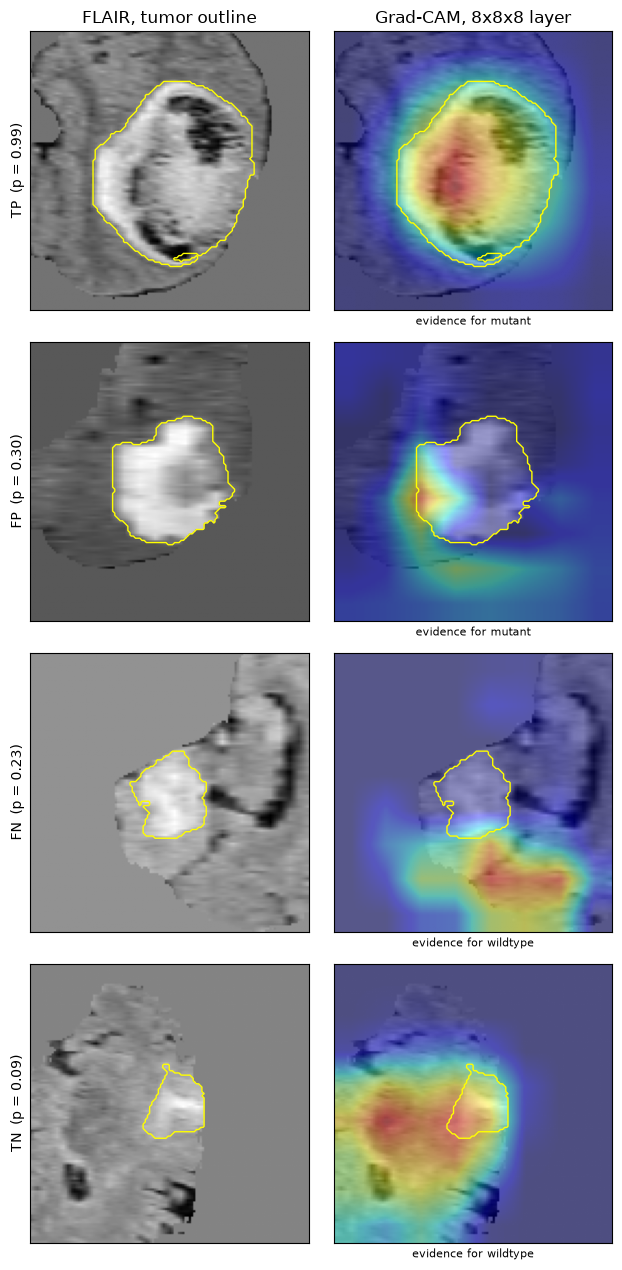

In [12]:
chosen = oof.groupby("group", group_keys=False).sample(1, random_state=SEED)
chosen = chosen.set_index("group").loc[["TP", "FP", "FN", "TN"]].reset_index()

fig, axes = plt.subplots(len(chosen), 2, figsize=(6.5, 3.2 * len(chosen)))
for row, r in zip(axes, chosen.itertuples()):
    image, tumor, _ = load_case(r.patient_id)
    m = get_model(int(r.fold))
    predicted_mutant = r.group in ("TP", "FP")
    _, cams = grad_cam(m, image, {LAYER_MAIN: layers_for(m)[LAYER_MAIN]},
                       sign=1.0 if predicted_mutant else -1.0)
    cam = cams[LAYER_MAIN]

    z = int(round(np.argwhere(tumor)[:, 0].mean()))          # slice through the tumor's centre
    base = image[3, z].numpy()                                # channel 3 = FLAIR
    for ax in row:
        ax.imshow(base, cmap="gray")
        ax.contour(tumor[z], levels=[0.5], colors="yellow", linewidths=1)
        ax.set_xticks([]); ax.set_yticks([])
    if cam.max() > 0:
        row[1].imshow(cam[z] / cam.max(), cmap="jet", alpha=0.4, vmin=0, vmax=1)
    row[0].set_ylabel(f"{r.group}  (p = {r.image_cnn_v2_prob:.2f})")
    row[1].set_xlabel(f"evidence for {'mutant' if predicted_mutant else 'wildtype'}", fontsize=8)

axes[0, 0].set_title("FLAIR, tumor outline")
axes[0, 1].set_title("Grad-CAM, 8x8x8 layer")
fig.tight_layout()
plt.show()

## 7. Takeaways and limitations

**What the results support**
- **Maps are tumor-centred and depend on what was learned.** At the 8 x 8 x 8 layer the median enrichment is 4.44 for true positives (IQR 3.03 to 6.12, 98% of maps above 1), 2.83 for false positives, 2.31 for false negatives and 0.07 for true negatives. The 4 x 4 x 4 layer gives the same ordering with lower values. A randomly initialized network gives non-empty maps for only 192 of 617 patients, median enrichment 0.00 among them and about all of the mass outside the brain, against 0.43 outside the brain for the trained model's true positives.
- **Much of the concentration is centering.** Another patient's tumor mask scores 3.75 on the same true-positive heatmaps, against 4.44 for the patient's own mask. The own mask scores higher in 63% to 65% of true positives, false positives and false negatives. There seems to be a modest tumor-specific component on top of crop centering, but not a strong one.
- **Most mass sits outside the tumor.** Even for true positives the median mass outside the brain is 0.43, and the tumor holds a minority of the rest. An all-zero input already produces a nonzero, nearly flat map (center-to-whole ratio 1.17 at 8 x 8 x 8, 0.96 at 4 x 4 x 4), so part of this is bias and padding artifact. Because that map is not additive, it cannot simply be subtracted.
- **Example figure.** In the four fixed examples the hot region sits on the tumor edge and surrounding tissue in the true positive and the false positive, and outside the tumor in the false negative and the true negative. This agrees with the group medians but is four patients and one slice each.

**Limitations**
- Descriptive medians and quartiles with no confidence intervals. The false-negative group has 33 patients and a very wide spread.
- The brain mask is "any channel non-zero", an approximation that relies on the exact-zero background after normalization.
- Heatmaps are shown for one layer, one slice and four patients. All scores are development estimates, and the external test (UCSF) has not been touched.